# Pristyn Care Health — Exploratory Analysis
**Checkpoint 2: Data pipeline + baseline metrics**

Yashwanth J V Nayak · Data Analyst Intern · Cynaris Solutions

This notebook is for exploration only — all production logic lives in `src/`. It calls the same pipeline functions used by `src/pipeline.py` so results here always match the pipeline's output.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import matplotlib.pyplot as plt

from src.utils import load_raw, clean_sales, clean_customers, check_referential_integrity
from src.metrics import channel_conversion_metrics, category_performance, customer_lifecycle_baseline

pd.set_option('display.max_columns', None)

## 1. Load & Clean

In [2]:
raw = load_raw()
sales = clean_sales(raw['sales'])
customers = clean_customers(raw['customers'])
products = raw['products']

print(f"Sales: {len(sales)} rows | Customers: {len(customers)} rows | Products: {len(products)} rows")
check_referential_integrity(sales, customers, products)

Sales: 1000 rows | Customers: 200 rows | Products: 50 rows


{'orphan_customer_ids': 0, 'orphan_product_ids': 0}

## 2. Baseline Customer Lifecycle Metrics

In [3]:
customer_lifecycle_baseline(customers)

{'total_customers': 200,
 'churned_customers': 6,
 'overall_churn_rate_pct': np.float64(3.0),
 'avg_orders_per_customer': np.float64(11.54),
 'avg_revenue_per_customer': np.float64(24963.1),
 'repeat_customer_rate_pct': np.float64(96.5)}

## 3. Channel-Level Conversion & Churn

In [4]:
channel_metrics = channel_conversion_metrics(sales, customers)
channel_metrics

,Channel,Transactions,Revenue,Customers,Churned,Churn_Rate_Pct,Revenue_Per_Customer
0,Website,249,2147641.40,57,0,0.00,37677.92
1,Offline,246,2052421.60,49,3,6.12,41886.16
2,Marketplace,255,1961555.35,43,1,2.33,45617.57
3,App,250,1860232.85,51,2,3.92,36475.15


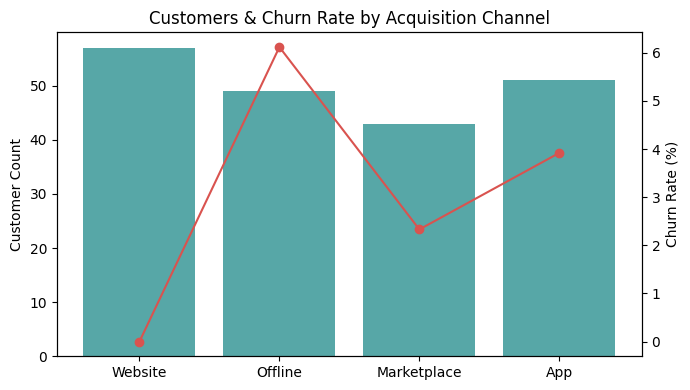

In [5]:
fig, ax1 = plt.subplots(figsize=(7,4))
ax1.bar(channel_metrics['Channel'], channel_metrics['Customers'], color='#1F8A8A', alpha=0.75)
ax1.set_ylabel('Customer Count')
ax2 = ax1.twinx()
ax2.plot(channel_metrics['Channel'], channel_metrics['Churn_Rate_Pct'], color='#D9534F', marker='o')
ax2.set_ylabel('Churn Rate (%)')
plt.title('Customers & Churn Rate by Acquisition Channel')
plt.tight_layout()
plt.show()

## 4. Category Performance (Revenue vs. Returns)

In [6]:
category_metrics = category_performance(sales)
category_metrics

,Category,Revenue,Transactions,Returns,Return_Rate_Pct
0,Apparel,1199522.90,152,13,8.55
1,Sports,1088806.35,143,14,9.79
2,Beauty,1037830.75,128,13,10.16
3,Home,1001012.90,113,11,9.73
4,Books,970256.55,124,11,8.87
5,Electronics,953494.00,113,11,9.73
6,Health,943798.30,125,10,8.00
7,Grocery,827129.45,102,14,13.73


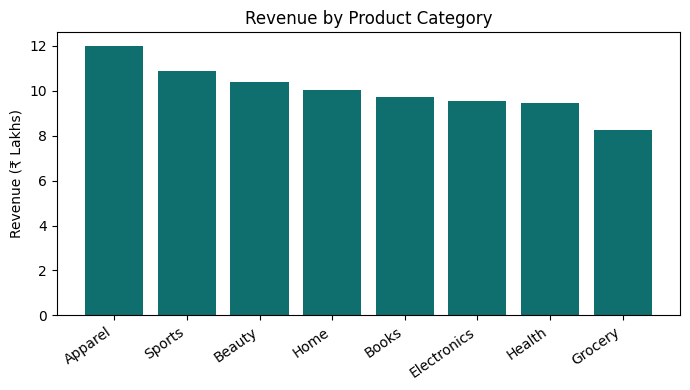

In [7]:
plt.figure(figsize=(7,4))
plt.bar(category_metrics['Category'], category_metrics['Revenue']/1e5, color='#0F6E6E')
plt.ylabel('Revenue (₹ Lakhs)')
plt.title('Revenue by Product Category')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## 5. Notes & Open Question

As flagged in the Milestone 1 data inventory, the source data has no funnel-stage fields (ad click → enquiry → consultation → diagnostics → booking → surgery → follow-up). The baseline metrics above use the closest available proxy — acquisition channel, first purchase, repeat orders, and churn — pending stakeholder confirmation on true funnel data.